In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
# DATA LOADING

df = pd.read_csv('data.csv')
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (43744, 9)


,Age,Gender,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score,Interest,Personality
0,21.0,Female,1,5.89208,2.144395,7.32363,5.462224,Arts,ENTP
1,24.0,Female,1,2.48366,3.206188,8.06876,3.765012,Unknown,INTP
2,26.0,Female,1,7.02910,6.469302,4.16472,5.454442,Others,ESFP
3,30.0,Male,0,5.46525,4.179244,2.82487,5.080477,Sports,ENFJ
4,31.0,Female,0,3.59804,6.189259,5.31347,3.677984,Others,ISFP


In [3]:
# Informasi dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43744 entries, 0 to 43743
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 43744 non-null  float64
 1   Gender              43744 non-null  str    
 2   Education           43744 non-null  int64  
 3   Introversion Score  43744 non-null  float64
 4   Sensing Score       43744 non-null  float64
 5   Thinking Score      43744 non-null  float64
 6   Judging Score       43744 non-null  float64
 7   Interest            43744 non-null  str    
 8   Personality         43744 non-null  str    
dtypes: float64(5), int64(1), str(3)
memory usage: 3.0 MB


In [4]:
# Menampilkan statistik deskriptif dari dataset
df.describe(include='all')

,Age,Gender,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score,Interest,Personality
count,43744.000000,43744,43744.000000,43744.000000,43744.000000,43744.000000,43744.000000,43744,43744
unique,NaN,2,NaN,NaN,NaN,NaN,NaN,5,16
top,NaN,Male,NaN,NaN,NaN,NaN,NaN,Unknown,ENTP
freq,NaN,24155,NaN,NaN,NaN,NaN,NaN,15396,2734
mean,27.437203,NaN,0.229014,4.588349,5.780074,5.419131,5.391041,NaN,NaN
std,4.893805,NaN,0.420203,2.902628,1.241648,2.900785,1.442413,NaN,NaN
min,18.000000,NaN,0.000000,0.000150,0.000000,0.000320,0.000000,NaN,NaN
25%,24.000000,NaN,0.000000,2.067020,4.953340,2.895750,4.511842,NaN,NaN
50%,27.000000,NaN,0.000000,4.261680,6.162928,5.769870,5.771635,NaN,NaN
75%,30.000000,NaN,0.000000,7.085002,6.622978,7.923503,6.409583,NaN,NaN


In [5]:
# Jumlah nilai unik setiap kolom
print("\nJumlah nilai unik:")
print(df.nunique())


Jumlah nilai unik:
Age                      35
Gender                    2
Education                 2
Introversion Score    41766
Sensing Score         42715
Thinking Score        41848
Judging Score         42661
Interest                  5
Personality              16
dtype: int64


In [6]:
# DATA CLEANING

# Mengecek missing values
missing_values = df.isnull().sum()
print("Missing value setiap kolom:")
print(missing_values)
print("\nTotal missing value:", missing_values.sum())

Missing value setiap kolom:
Age                   0
Gender                0
Education             0
Introversion Score    0
Sensing Score         0
Thinking Score        0
Judging Score         0
Interest              0
Personality           0
dtype: int64

Total missing value: 0


In [7]:
# Mengeck data duplikat
duplicateds = df.duplicated()
print("\nJumlah baris duplikat:", duplicateds.sum())
print("Baris duplikat:")
print(df[duplicateds])


Jumlah baris duplikat: 1028
Baris duplikat:
        Age  Gender  Education  Introversion Score  Sensing Score  \
280    27.0    Male          0             2.60443       6.675294   
329    36.0  Female          0             1.53097       6.934363   
976    28.0    Male          0             0.25266       7.117046   
1179   29.0  Female          0             0.73079       6.191384   
1295   28.0    Male          0             4.48857       7.159351   
...     ...     ...        ...                 ...            ...   
43441  28.0    Male          0             1.90482       6.350893   
43691  28.0    Male          0             3.43054       7.050276   
43715  41.0    Male          0             5.08423       6.308160   
43737  27.0    Male          0             1.94868       7.035653   
43741  25.0  Female          0             2.00982       6.544036   

       Thinking Score  Judging Score    Interest Personality  
280           6.95374       6.948383     Unknown        ISTJ  


In [8]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikat:", df.shape)

DataFrame setelah menghapus duplikat: (42716, 9)


In [9]:
# Memastikan target tidak kosong
df = df.dropna(subset=['Personality']).copy()
print("Jumlah baris setelah menghapus data kosong:", len(df))

Jumlah baris setelah menghapus data kosong: 42716


In [10]:
# Memeriksa nilai kosong setelah cleaning
print("Missing value setelah cleaning:")
print(df.isnull().sum())

Missing value setelah cleaning:
Age                   0
Gender                0
Education             0
Introversion Score    0
Sensing Score         0
Thinking Score        0
Judging Score         0
Interest              0
Personality           0
dtype: int64


In [11]:
# Memeriksa kategori Gender dan Interest
print("\nKategori Gender:")
print(df["Gender"].value_counts(dropna=False))

print("\nKategori Interest:")
print(df["Interest"].value_counts(dropna=False))



Kategori Gender:
Gender
Male      23598
Female    19118
Name: count, dtype: int64

Kategori Interest:
Interest
Unknown       15087
Arts           8249
Sports         6774
Others         6654
Technology     5952
Name: count, dtype: int64


In [12]:
# Memeriksa nilai numerik yang tidak valid
num_cols = [
    "Age",
    "Education",
    "Introversion Score",
    "Sensing Score",
    "Thinking Score",
    "Judging Score"
]

print("\nStatistik fitur numerik:")
display(df[num_cols].describe().T)


Statistik fitur numerik:


,count,mean,std,min,25%,50%,75%,max
Age,42716.0,27.399874,4.896950,18.00000,24.000000,27.000000,30.000000,52.000000
Education,42716.0,0.234455,0.423663,0.00000,0.000000,0.000000,0.000000,1.000000
Introversion Score,42716.0,4.648648,2.903699,0.00015,2.126148,4.366155,7.150157,9.999920
Sensing Score,42716.0,5.757710,1.245533,0.00000,4.921852,6.146764,6.610954,9.803837
Thinking Score,42716.0,5.357428,2.901552,0.00032,2.830253,5.663500,7.866093,9.999770
Judging Score,42716.0,5.366713,1.448086,0.00000,4.480033,5.723904,6.397870,10.000000


In [13]:
# EDA 
# Statisik Deskriptif Fitur Numerik dan Kategorikal
num_cols = [
    "Age",
    "Education",
    "Introversion Score",
    "Sensing Score",
    "Thinking Score",
    "Judging Score"
]

cat_cols = ["Gender", "Interest"]
target = "Personality"

# Pastikan kolom yang diperlukan tersedia
required_cols = num_cols + cat_cols + [target]
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Kolom berikut tidak ditemukan: {missing_cols}")

print("Statistik deskriptif fitur numerik:")
display(df[num_cols].describe().T)

print("Statistik deskriptif fitur kategorikal:")
display(df[cat_cols].describe().T)

Statistik deskriptif fitur numerik:


,count,mean,std,min,25%,50%,75%,max
Age,42716.0,27.399874,4.896950,18.00000,24.000000,27.000000,30.000000,52.000000
Education,42716.0,0.234455,0.423663,0.00000,0.000000,0.000000,0.000000,1.000000
Introversion Score,42716.0,4.648648,2.903699,0.00015,2.126148,4.366155,7.150157,9.999920
Sensing Score,42716.0,5.757710,1.245533,0.00000,4.921852,6.146764,6.610954,9.803837
Thinking Score,42716.0,5.357428,2.901552,0.00032,2.830253,5.663500,7.866093,9.999770
Judging Score,42716.0,5.366713,1.448086,0.00000,4.480033,5.723904,6.397870,10.000000


Statistik deskriptif fitur kategorikal:


,count,unique,top,freq
Gender,42716,2,Male,23598
Interest,42716,5,Unknown,15087


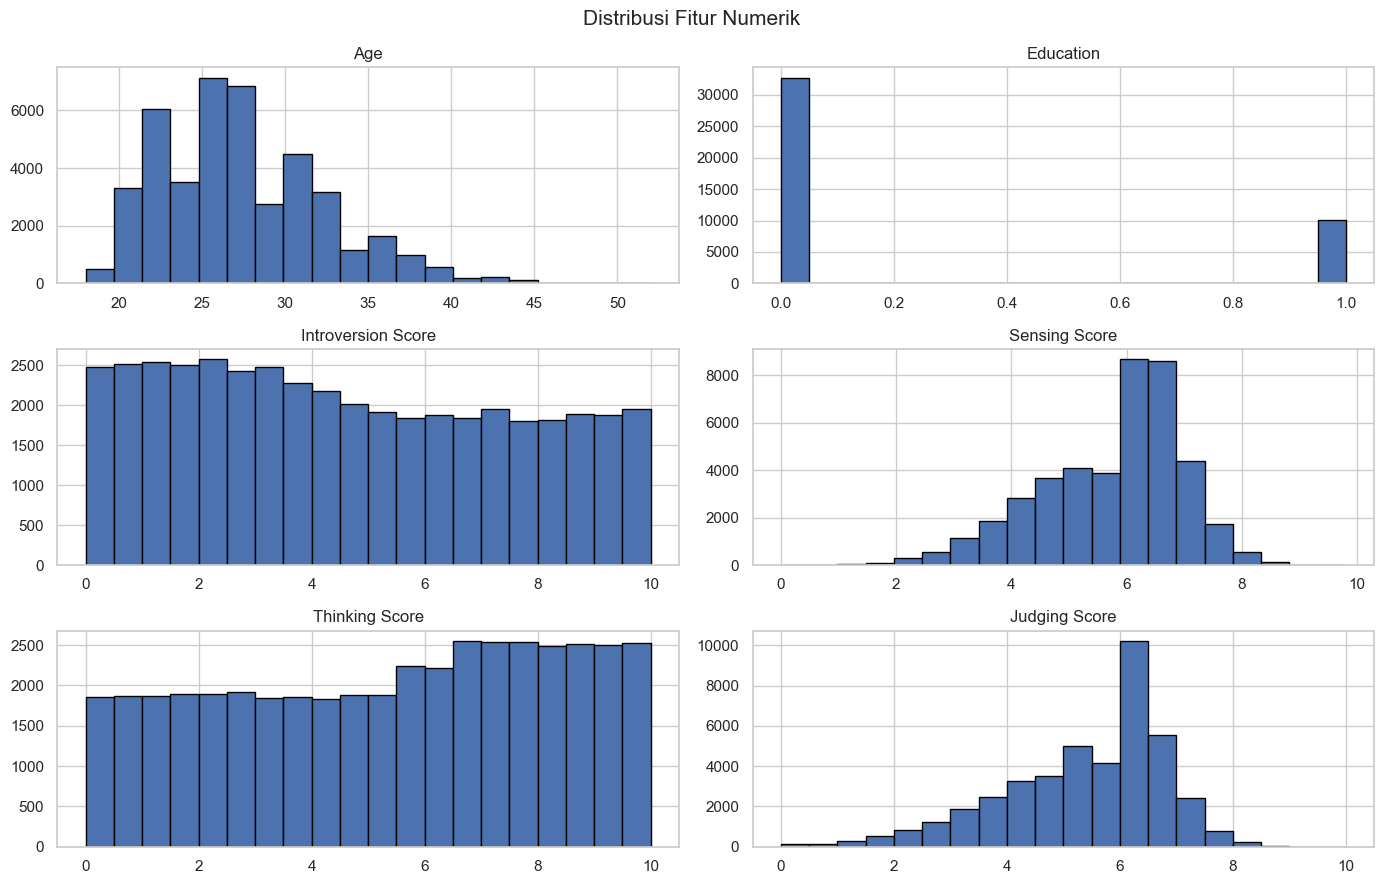

In [14]:
# Visualisasi Distribusi Fitur Numerik   
df[num_cols].hist(
    bins=20,
    figsize=(14, 9),
    edgecolor="black"
)

plt.suptitle("Distribusi Fitur Numerik", fontsize=15)
plt.tight_layout()
plt.show()

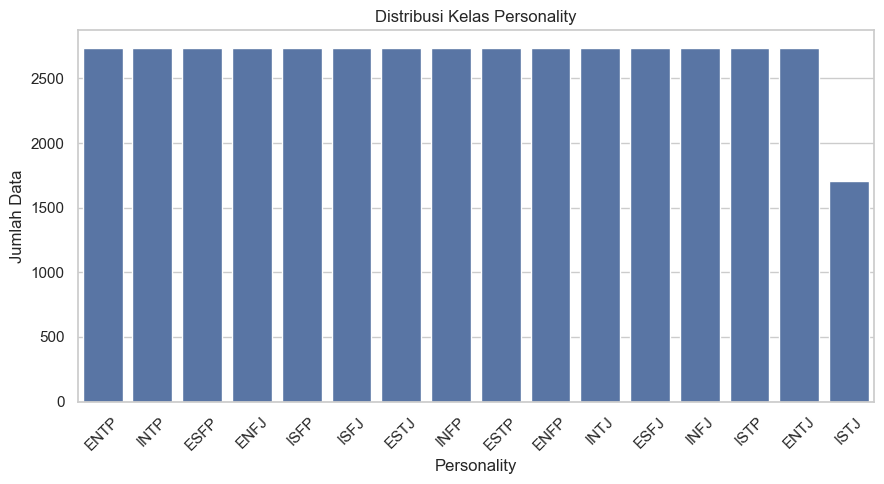

Personality
ENTP    2734
INTP    2734
ESFP    2734
ENFJ    2734
ISFP    2734
ISFJ    2734
ESTJ    2734
INFP    2734
ESTP    2734
ENFP    2734
INTJ    2734
ESFJ    2734
INFJ    2734
ISTP    2734
ENTJ    2734
ISTJ    1706
Name: count, dtype: int64

Proporsi kelas (%):
Personality
ENTP    6.40
INTP    6.40
ESFP    6.40
ENFJ    6.40
ISFP    6.40
ISFJ    6.40
ESTJ    6.40
INFP    6.40
ESTP    6.40
ENFP    6.40
INTJ    6.40
ESFJ    6.40
INFJ    6.40
ISTP    6.40
ENTJ    6.40
ISTJ    3.99
Name: proportion, dtype: float64


In [15]:
# Visualisasi Distribusi Kelas Target
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Personality",
    order=df["Personality"].value_counts().index
)

plt.title("Distribusi Kelas Personality")
plt.xlabel("Personality")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(df["Personality"].value_counts())
print("\nProporsi kelas (%):")
print((df["Personality"].value_counts(normalize=True) * 100).round(2))

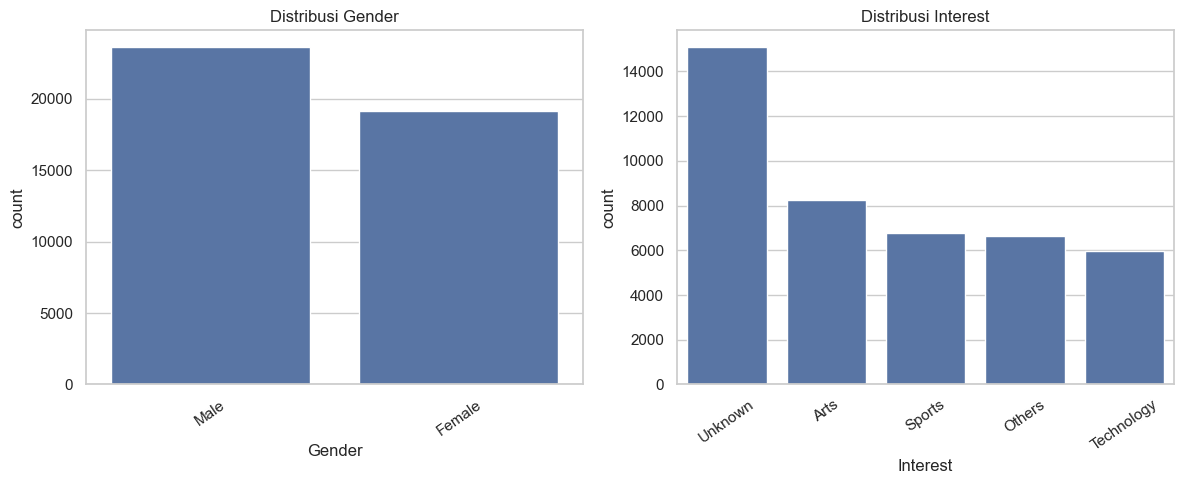

In [16]:
# Visualisasi Distribusi Fitur Kategorikal
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for col, ax in zip(cat_cols, axes):
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=ax
    )
    ax.set_title(f"Distribusi {col}")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

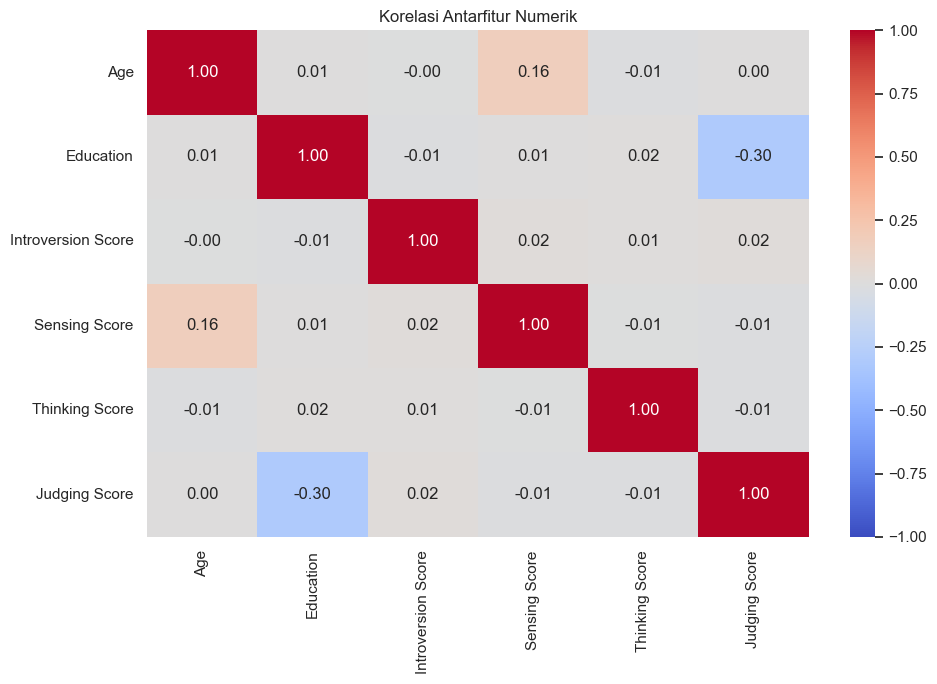

In [17]:
# Korelasi Antarfitur Numerik
plt.figure(figsize=(10, 7))

corr = df[num_cols].corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Korelasi Antarfitur Numerik")
plt.tight_layout()
plt.show()

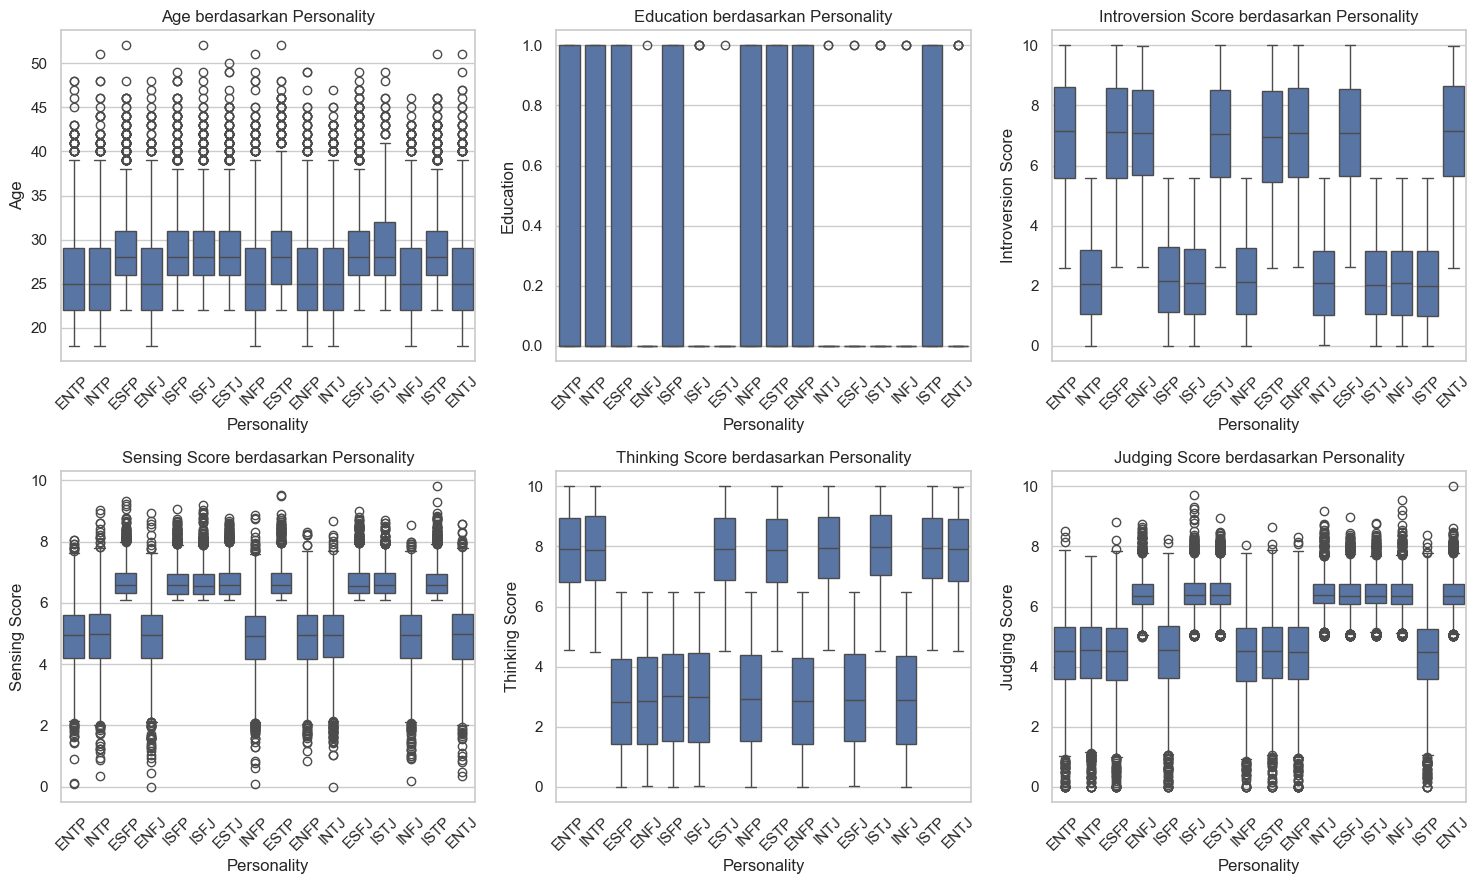

In [18]:
# ExDA
# Hubungan Fitur Numerik dengan Target
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, ax in zip(num_cols, axes.flatten()):
    sns.boxplot(
        data=df,
        x="Personality",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} berdasarkan Personality")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

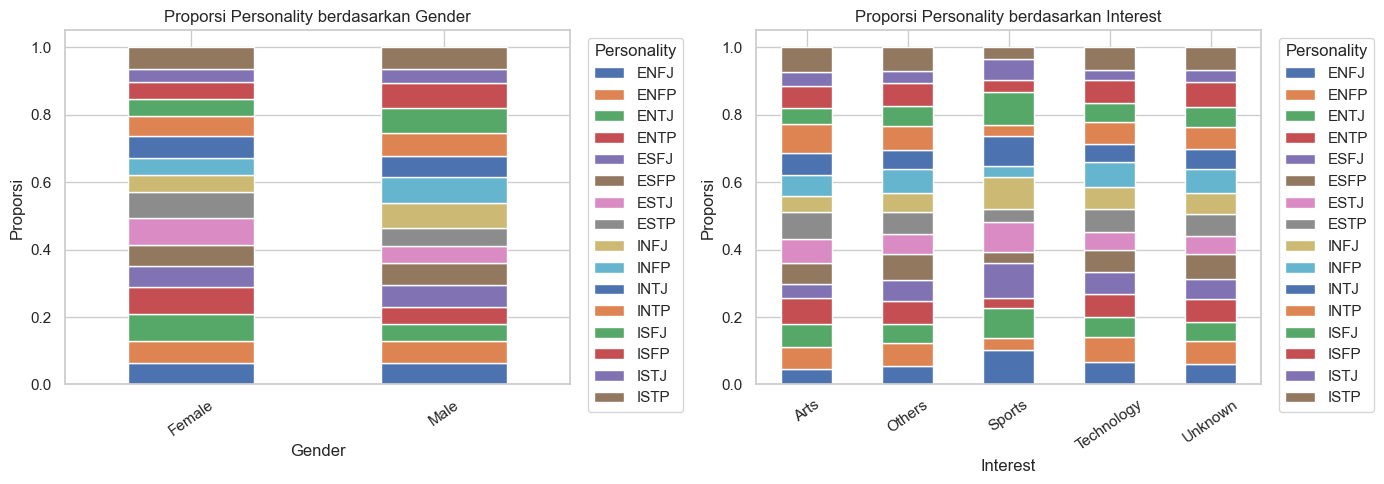

In [19]:
# Hubungan Fitur Kategorikal dengan Target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for col, ax in zip(cat_cols, axes):
    proporsi = pd.crosstab(
        df[col],
        df["Personality"],
        normalize="index"
    )

    proporsi.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(f"Proporsi Personality berdasarkan {col}")
    ax.set_ylabel("Proporsi")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Personality", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

In [20]:
# Ringkasan karakteristik setiap kelas
print("Rata-rata fitur numerik per Personality:")
display(
    df.groupby("Personality")[num_cols]
      .mean()
      .round(2)
)

print("Jumlah Personality berdasarkan Gender:")
display(pd.crosstab(df["Gender"], df["Personality"]))

print("Jumlah Personality berdasarkan Interest:")
display(pd.crosstab(df["Interest"], df["Personality"]))

Rata-rata fitur numerik per Personality:


,Age,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score
Personality,,,,,,
ENFJ,26.05,0.00,7.03,4.87,2.92,6.42
ENFP,26.01,0.45,7.02,4.86,2.90,4.36
ENTJ,25.87,0.00,7.05,4.89,7.86,6.42
ENTP,25.87,0.46,7.02,4.86,7.84,4.37
ESFJ,28.76,0.00,7.01,6.69,2.97,6.40
ESFP,28.91,0.45,7.00,6.71,2.90,4.37
ESTJ,28.90,0.00,6.98,6.71,7.87,6.43
ESTP,28.81,0.46,6.91,6.71,7.82,4.39
INFJ,26.03,0.00,2.16,4.86,2.94,6.40


Jumlah Personality berdasarkan Gender:


Personality,ENFJ,ENFP,ENTJ,ENTP,ESFJ,ESFP,ESTJ,ESTP,INFJ,INFP,INTJ,INTP,ISFJ,ISFP,ISTJ,ISTP
Gender,,,,,,,,,,,,,,,,
Female,1225,1214,1545,1528,1186,1237,1483,1480,985,937,1251,1167,961,954,737,1228
Male,1509,1520,1189,1206,1548,1497,1251,1254,1749,1797,1483,1567,1773,1780,969,1506


Jumlah Personality berdasarkan Interest:


Personality,ENFJ,ENFP,ENTJ,ENTP,ESFJ,ESFP,ESTJ,ESTP,INFJ,INFP,INTJ,INTP,ISFJ,ISFP,ISTJ,ISTP
Interest,,,,,,,,,,,,,,,,
Arts,389,526,553,640,346,509,592,655,398,511,545,699,406,535,330,615
Others,368,459,360,459,419,514,391,427,382,469,376,480,399,446,244,461
Sports,683,249,610,201,693,233,604,243,651,226,604,213,673,242,406,243
Technology,395,435,359,415,379,389,328,402,382,435,324,385,348,394,189,393
Unknown,899,1065,852,1019,897,1089,819,1007,921,1093,885,957,908,1117,537,1022


In [21]:
# SPLITTING DATA

# Memisahkan fitur dan target
X = df.drop(columns=["Personality"])
y = df["Personality"]

# Menampilkan data sebelum split
print("Data sebelum split")
print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data setelah split")
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])

print("Jumlah fitur:", X_train.shape[1])

Data sebelum split
Jumlah data: 42716
Jumlah fitur: 8
Data setelah split
Jumlah data training: 34172
Jumlah data testing : 8544
Jumlah fitur: 8


In [22]:
# PREPROCESSING DATA

# Encoding untuk Target (y)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)  # Fit di train
y_test_encoded = label_encoder.transform(y_test)        # Transform di test

In [23]:

# One-Hot Encoding untuk Fitur Kategorikal 
cat_cols = ['Gender', 'Interest']
encoder = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ],
    remainder="passthrough"
)

print("Fitur numerik:", num_cols)
print("Fitur kategorikal:", cat_cols)


Fitur numerik: ['Age', 'Education', 'Introversion Score', 'Sensing Score', 'Thinking Score', 'Judging Score']
Fitur kategorikal: ['Gender', 'Interest']


In [24]:
# Fit dan transform data training
X_train_encoded = encoder.fit_transform(X_train)

# Transform data testing
X_test_encoded = encoder.transform(X_test)

print("Ukuran data training setelah encoding:", X_train_encoded.shape)
print("Ukuran data testing setelah encoding:", X_test_encoded.shape)

Ukuran data training setelah encoding: (34172, 13)
Ukuran data testing setelah encoding: (8544, 13)


In [25]:
# Scaling 

# Kolom numerik
num_cols = [
    "Age",
    "Education",
    "Introversion Score",
    "Sensing Score",
    "Thinking Score",
    "Judging Score"
]

# Data sebelum scaling
print("Data training sebelum scaling:")
display(X_train[num_cols].head())

print("Data testing sebelum scaling:")
display(X_test[num_cols].head())


Data training sebelum scaling:


,Age,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score
40099,33.0,0,2.07691,4.919314,2.32661,6.606121
39952,29.0,0,2.15524,5.104759,3.73480,6.167461
25997,23.0,0,1.57697,3.019281,2.37299,5.068143
3637,27.0,1,7.20907,6.241548,6.08274,5.317241
5876,28.0,0,6.13853,7.342830,7.31704,6.025014


Data testing sebelum scaling:


,Age,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score
5005,26.0,0,3.02390,6.027888,1.71874,3.487627
21278,28.0,0,2.63951,6.882188,9.94029,4.552157
28809,37.0,0,2.02925,4.738719,7.39876,6.436763
11365,20.0,0,9.22560,6.075328,4.01959,6.589080
22581,21.0,0,2.22857,6.508681,9.47486,6.631999


In [26]:
# Scaling fitur numerik
scaler = StandardScaler()

X_train_scaled = X_train[num_cols].copy()
X_test_scaled = X_test[num_cols].copy()

X_train_scaled[num_cols] = scaler.fit_transform(
    X_train[num_cols]
)

X_test_scaled[num_cols] = scaler.transform(
    X_test[num_cols]
)

# Data setelah scaling
print("Data training setelah scaling:")
display(X_train_scaled.head())

print("Data testing setelah scaling:")
display(X_test_scaled.head())

Data training setelah scaling:


,Age,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score
40099,1.137483,-0.552062,-0.885006,-0.674037,-1.044774,0.855898
39952,0.322832,-0.552062,-0.858031,-0.524808,-0.558931,0.553267
25997,-0.899145,-0.552062,-1.057169,-2.203011,-1.028772,-0.205152
3637,-0.084494,1.811390,0.882350,0.389976,0.251136,-0.033299
5876,0.119169,-0.552062,0.513690,1.276188,0.676984,0.454993


Data testing setelah scaling:


,Age,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score
5005,-0.288157,-0.552062,-0.558892,0.218043,-1.254496,-1.295550
21278,0.119169,-0.552062,-0.691264,0.905505,1.582037,-0.561130
28809,1.952135,-0.552062,-0.901418,-0.819364,0.705179,0.739058
11365,-1.510134,-0.552062,1.576780,0.256218,-0.460675,0.844142
22581,-1.306471,-0.552062,-0.832779,0.604941,1.421458,0.873752


In [27]:
# Mengubah hasil encoding menjadi DataFrame
X_train_cat = pd.DataFrame(
    X_train_encoded,
    columns=encoder.get_feature_names_out(),
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_encoded,
    columns=encoder.get_feature_names_out(),
    index=X_test.index
)

# Menggabungkan fitur numerik dan kategorikal
X_train_final = pd.concat([X_train_scaled, X_train_cat], axis=1)
X_test_final = pd.concat([X_test_scaled, X_test_cat], axis=1)

print("Ukuran training:", X_train_final.shape)
print("Ukuran testing:", X_test_final.shape)

display(X_train_final.head())

Ukuran training: (34172, 19)
Ukuran testing: (8544, 19)


,Age,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score,cat__Gender_Female,cat__Gender_Male,cat__Interest_Arts,cat__Interest_Others,cat__Interest_Sports,cat__Interest_Technology,cat__Interest_Unknown,remainder__Age,remainder__Education,remainder__Introversion Score,remainder__Sensing Score,remainder__Thinking Score,remainder__Judging Score
40099,1.137483,-0.552062,-0.885006,-0.674037,-1.044774,0.855898,1.0,0.0,1.0,0.0,0.0,0.0,0.0,33.0,0.0,2.07691,4.919314,2.32661,6.606121
39952,0.322832,-0.552062,-0.858031,-0.524808,-0.558931,0.553267,0.0,1.0,1.0,0.0,0.0,0.0,0.0,29.0,0.0,2.15524,5.104759,3.73480,6.167461
25997,-0.899145,-0.552062,-1.057169,-2.203011,-1.028772,-0.205152,0.0,1.0,0.0,0.0,0.0,0.0,1.0,23.0,0.0,1.57697,3.019281,2.37299,5.068143
3637,-0.084494,1.811390,0.882350,0.389976,0.251136,-0.033299,1.0,0.0,0.0,1.0,0.0,0.0,0.0,27.0,1.0,7.20907,6.241548,6.08274,5.317241
5876,0.119169,-0.552062,0.513690,1.276188,0.676984,0.454993,1.0,0.0,0.0,1.0,0.0,0.0,0.0,28.0,0.0,6.13853,7.342830,7.31704,6.025014


In [28]:
num_cols = [
    "Age",
    "Education",
    "Introversion Score",
    "Sensing Score",
    "Thinking Score",
    "Judging Score"
]

cat_cols = ["Gender", "Interest"]

# Preprocessing Random Forest
preprocessor_rf = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# Preprocessing Logistic Regression
preprocessor_lr = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])


In [29]:
# MODELING DATA
# Pipeline Random Forest
rf_model = Pipeline([
    ("preprocessing", preprocessor_rf),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ))
])

# Pipeline Logistic Regression
lr_model = Pipeline([
    ("preprocessing", preprocessor_lr),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Pipeline berhasil dibuat.")

Pipeline berhasil dibuat.


In [30]:
# Training Random Forest
rf_model.fit(X_train, y_train)

# Training Logistic Regression
lr_model.fit(X_train, y_train)

print("Kedua model berhasil dilatih.")

Kedua model berhasil dilatih.


In [31]:
# Prediksi menggunakan data testing
y_pred_rf = rf_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test)

print("Prediksi Random Forest selesai.")
print("Prediksi Logistic Regression selesai.")

Prediksi Random Forest selesai.
Prediksi Logistic Regression selesai.


In [32]:
# Hasil prediksi
hasil_prediksi = pd.DataFrame({
    "Aktual": y_test,
    "Prediksi Random Forest": y_pred_rf,
    "Prediksi Logistic Regression": y_pred_lr
})

display(hasil_prediksi.head(10))

,Aktual,Prediksi Random Forest,Prediksi Logistic Regression
5005,INFP,INFP,INFP
21278,ISTP,ISTP,ISTP
28809,INTJ,INTJ,INTJ
11365,ENFJ,ENFJ,ENFJ
22581,INTJ,INTJ,INTJ
10991,ESTJ,ESTJ,ESTJ
11143,ISTP,ISTP,ISTJ
15521,ENTP,ENTP,ENTP
7231,ENTJ,ENTJ,ENTJ
528,INFJ,INFJ,INFJ


In [33]:
# EVALUASI MODEL
hasil_evaluasi = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(
            y_test, y_pred_rf,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_rf,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred_rf,
            average="weighted", zero_division=0
        )
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(
            y_test, y_pred_lr,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_lr,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred_lr,
            average="weighted", zero_division=0
        )
    }
])

print("Tabel hasil evaluasi:")
display(hasil_evaluasi.round(4))

Tabel hasil evaluasi:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.9000,0.9010,0.9000,0.9000
1,Logistic Regression,0.8533,0.8552,0.8533,0.8533


In [34]:
# Klasifikasi Laporan
from sklearn.metrics import classification_report

print("RANDOM FOREST")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

print("=== LOGISTIC REGRESSION ===")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

RANDOM FOREST
              precision    recall  f1-score   support

        ENFJ       0.91      0.89      0.90       547
        ENFP       0.91      0.86      0.89       547
        ENTJ       0.93      0.90      0.91       547
        ENTP       0.92      0.87      0.90       547
        ESFJ       0.90      0.89      0.89       547
        ESFP       0.90      0.90      0.90       547
        ESTJ       0.92      0.94      0.93       547
        ESTP       0.91      0.90      0.91       547
        INFJ       0.92      0.88      0.90       547
        INFP       0.89      0.87      0.88       546
        INTJ       0.92      0.91      0.92       547
        INTP       0.91      0.86      0.88       546
        ISFJ       0.87      0.94      0.90       547
        ISFP       0.86      0.93      0.89       547
        ISTJ       0.88      0.91      0.90       341
        ISTP       0.85      0.94      0.90       547

    accuracy                           0.90      8544
   macro avg

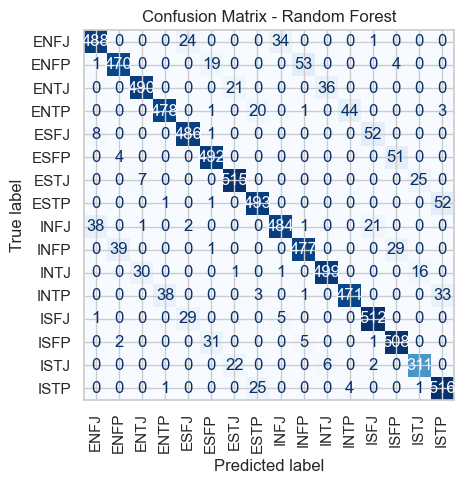

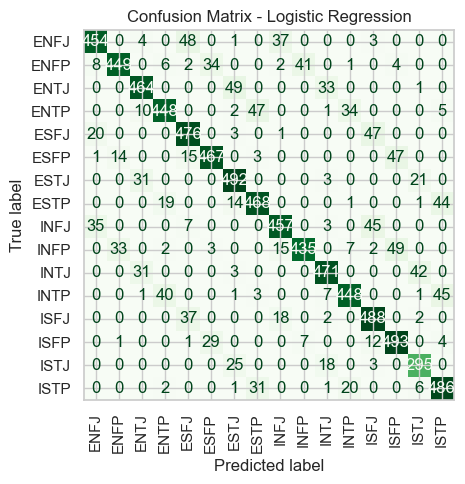

In [35]:
# Confusion Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    xticks_rotation="vertical",
    cmap="Greens",
    colorbar=False
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [36]:
# Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)

lr_cv = cross_val_score(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)

print("Random Forest CV F1:", rf_cv)
print("Rata-rata Random Forest:", round(rf_cv.mean(), 4))

print("\nLogistic Regression CV F1:", lr_cv)
print("Rata-rata Logistic Regression:", round(lr_cv.mean(), 4))

Random Forest CV F1: [0.89678054 0.89296839 0.89834452 0.89765641 0.89881483]
Rata-rata Random Forest: 0.8969

Logistic Regression CV F1: [0.84409029 0.84774974 0.84790793 0.85153573 0.85318824]
Rata-rata Logistic Regression: 0.8489


In [41]:
# Menentukan model terbaik berdasarkan F1-Score
indeks_terbaik = hasil_evaluasi["F1-Score"].idxmax()

nama_model_terbaik = hasil_evaluasi.loc[indeks_terbaik, "Model"]

print("Model terbaik:", nama_model_terbaik)

Model terbaik: Random Forest


In [40]:
models = {
    "Random Forest": rf_model,
    "Logistic Regression": lr_model
}

model_terbaik = models[nama_model_terbaik]

print("Pipeline model terbaik berhasil dipilih.")

Pipeline model terbaik berhasil dipilih.


In [42]:
import joblib

# Menyimpan model terbaik beserta preprocessing-nya
joblib.dump(model_terbaik, "model_personality.pkl")

print("Model berhasil disimpan.")

Model berhasil disimpan.


In [53]:
# DEPLOYMENT
import joblib
model = joblib.load("model_personality.pkl")
print("Model berhasil dimuat.")

# Mengambil satu data sebagai simulasi data baru
data_baru = X_test.iloc[[0]]
prediksi = model.predict(data_baru)
print("Hasil prediksi:", prediksi[0])

# Menghitung probabilitas prediksi
probabilitas = model.predict_proba(data_baru)
for kelas, prob in zip(model.classes_, probabilitas[0]):
    print(f"{kelas}: {prob:.4f}")

# Prediksi
hasil_prediksi = model.predict(data_baru)
print("Hasil prediksi:", hasil_prediksi)

Model berhasil dimuat.
Hasil prediksi: INFP
ENFJ: 0.0050
ENFP: 0.0600
ENTJ: 0.0000
ENTP: 0.0150
ESFJ: 0.0000
ESFP: 0.0050
ESTJ: 0.0000
ESTP: 0.0000
INFJ: 0.0550
INFP: 0.8000
INTJ: 0.0050
INTP: 0.0100
ISFJ: 0.0050
ISFP: 0.0400
ISTJ: 0.0000
ISTP: 0.0000
Hasil prediksi: ['INFP']


In [47]:
import pandas as pd
from datetime import datetime

hasil_monitoring = pd.DataFrame({
    "waktu": [datetime.now()],
    "hasil_prediksi": [hasil_prediksi[0]]
})

display(hasil_monitoring)

,waktu,hasil_prediksi
0,2026-10-12 20:11:45.461238,INFP
